# Кластеризация ЕГЭ (8.5 если сделаны все задачи)

Рядом лежат экселевские таблицы с координатами точек. В 3 и 4 задаче используется манхетеское расстояние. В остальных Евклидово.

* Постройте Распределение точек
* Кластеризуйте руками
* Постройте Распределение точек, отметьте принадлежность кластеров цветами
* Найдите среди в каждом кластере точку расстояние от которой до всех остальных минимально
* Выведите усреднение центров всех кластеров * 1000

Ответ: 8186.804380062371 738.5877609048638


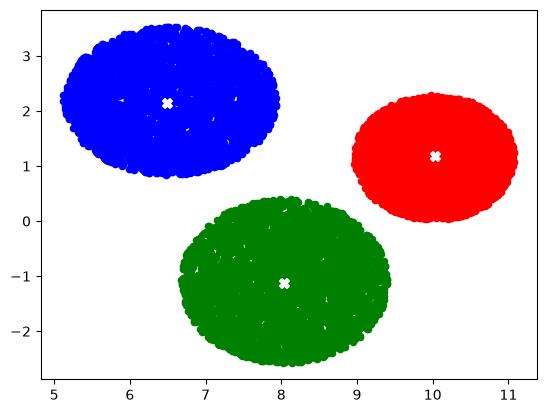

In [81]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random
import math


def rast(x1, y1, x2, y2):
    return math.sqrt(float(x1 - x2) ** 2 + float(y1 - y2) ** 2)


df1 = pd.read_excel('/Users/viarg/Downloads/cluster_ege/EGE/1.xls', header=None, skiprows = 1)
plt.scatter(df1.iloc[:, 0].values, df1.iloc[:, 1].values, color = 'red', s = 0.1)

toch = df1.iloc[:, :2].values

i1 = random.randint(0, len(toch) - 1)
i2 = random.randint(0, len(toch) - 1)
i3 = random.randint(0, len(toch) - 1)
while i2 == i1:
    i2 = random.randint(0, len(toch) - 1)
while i3 == i2:
    i3 = random.randint(0, len(toch) - 1)

c1 = toch[i1]
c2 = toch[i2]
c3 = toch[i3]

s11 = 0
s12 = 0
s21 = 0
s22 = 0
s31 = 0
s32 = 0

p1 = []
p2 = []
p3 = []

for i in range(len(toch)):
    x3 = toch[i][0]
    y3 = toch[i][1]
    r1 = rast(c1[0], c1[1], x3, y3)
    r2 = rast(c2[0], c2[1], x3, y3)
    r3 = rast(c3[0], c3[1], x3, y3)
    
    if min(r1, r2, r3) == r1:
        s11 += x3
        s12 += y3
        p1.append((x3, y3))
        c1[0] = s11 / len(p1)
        c1[1] = s12 / len(p1)
    elif min(r1, r2, r3) == r2:
        s21 += x3
        s22 += y3
        p2.append((x3, y3))
        c2[0] = s21 / len(p2)
        c2[1] = s22 / len(p2)
    else:
        s31 += x3
        s32 += y3
        p3.append((x3, y3))
        c3[0] = s31 / len(p3)
        c3[1] = s32 / len(p3)


        
p1 = np.array(p1)
p2 = np.array(p2)
p3 = np.array(p3)

x_p1 = p1[:, 0]
y_p1 = p1[:, 1]

x_p2 = p2[:, 0]
y_p2 = p2[:, 1]

x_p3 = p3[:, 0]
y_p3 = p3[:, 1]

diff = p1[:, np.newaxis, :] - p1[np.newaxis, :, :]
distances = np.sqrt((diff ** 2).sum(axis=-1))
sums = distances.sum(axis=1)
ind1 = np.argmin(sums)

plt.scatter(p1[ind1][0], p1[ind1][1], color = 'white', s = 50, marker = 'X', zorder=10)

diff = p2[:, np.newaxis, :] - p2[np.newaxis, :, :]
distances = np.sqrt((diff ** 2).sum(axis=-1))
sums = distances.sum(axis=1)
ind2 = np.argmin(sums)

plt.scatter(p2[ind2][0], p2[ind2][1], color = 'white', s = 50, marker = 'X', zorder=10)

diff = p3[:, np.newaxis, :] - p3[np.newaxis, :, :]
distances = np.sqrt((diff ** 2).sum(axis=-1))
sums = distances.sum(axis=1)
ind3 = np.argmin(sums)

plt.scatter(p3[ind3][0], p3[ind3][1], color = 'white', s = 50, marker = 'X', zorder=10)

all = np.array([p1[ind1], p2[ind2], p3[ind3]])
print("Ответ:", *np.mean(all, axis=0) * 1000)

plt.scatter(x_p1, y_p1, color='red', s=20)
plt.scatter(x_p2, y_p2, color='blue', s=20)

plt.scatter(x_p3, y_p3, color='green', s=20)

plt.show()


Ответ: 1146.830330364559 6559.594690151465


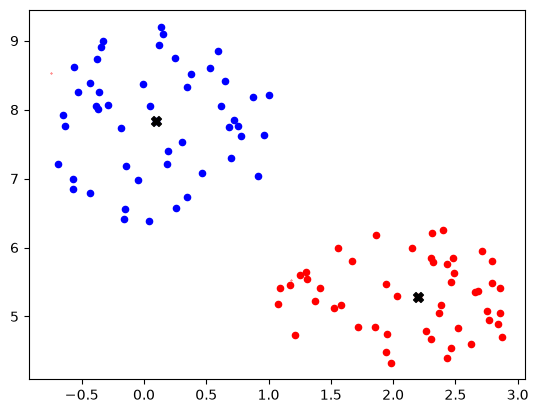

In [83]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random
import math


def rast(x1, y1, x2, y2):
    return math.sqrt(float(x1 - x2) ** 2 + float(y1 - y2) ** 2)


df1 = pd.read_excel('/Users/viarg/Downloads/cluster_ege/EGE/0.xls', header=None, skiprows = 1)
plt.scatter(df1.iloc[:, 0].values, df1.iloc[:, 1].values, color = 'red', s = 0.1)

toch = df1.iloc[:, :2].values

i1 = random.randint(0, len(toch) - 1)
i2 = random.randint(0, len(toch) - 1)
while i2 == i1:
    i2 = random.randint(0, len(toch) - 1)


c1 = toch[i1]
c2 = toch[i2]

s11 = 0
s12 = 0
s21 = 0
s22 = 0

p1 = []
p2 = []
for i in range(len(toch)):
    x3 = toch[i][0]
    y3 = toch[i][1]
    r1 = rast(c1[0], c1[1], x3, y3)
    r2 = rast(c2[0], c2[1], x3, y3)
    
    if min(r1, r2) == r1:
        s11 += x3
        s12 += y3
        p1.append((x3, y3))
        c1[0] = s11 / len(p1)
        c1[1] = s12 / len(p1)
    else:
        s21 += x3
        s22 += y3
        p2.append((x3, y3))
        c2[0] = s21 / len(p2)
        c2[1] = s22 / len(p2)


        
p1 = np.array(p1)
p2 = np.array(p2)

x_p1 = p1[:, 0]
y_p1 = p1[:, 1]

x_p2 = p2[:, 0]
y_p2 = p2[:, 1]

diff = p1[:, np.newaxis, :] - p1[np.newaxis, :, :]
distances = np.sqrt((diff ** 2).sum(axis=-1))
sums = distances.sum(axis=1)
ind1 = np.argmin(sums)

plt.scatter(p1[ind1][0], p1[ind1][1], color = 'black', s = 50, marker = 'X', zorder=10)

diff = p2[:, np.newaxis, :] - p2[np.newaxis, :, :]
distances = np.sqrt((diff ** 2).sum(axis=-1))
sums = distances.sum(axis=1)
ind2 = np.argmin(sums)

plt.scatter(p2[ind2][0], p2[ind2][1], color = 'black', s = 50, marker = 'X', zorder=10)

all = np.array([p1[ind1], p2[ind2]])
print("Ответ:", *np.mean(all, axis=0) * 1000)

plt.scatter(x_p1, y_p1, color='red', s=20)
plt.scatter(x_p2, y_p2, color='blue', s=20)


plt.show()


Ответ: 23229.654392165543 724.4967458817029


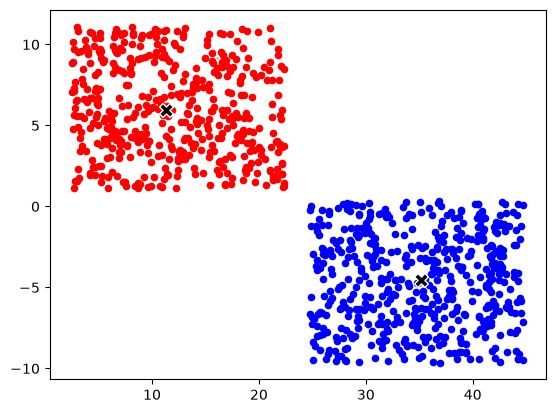

In [90]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random
import math


def rast(x1, y1, x2, y2):
    return math.sqrt(float(x1 - x2) ** 2 + float(y1 - y2) ** 2)


df1 = pd.read_excel('/Users/viarg/Downloads/cluster_ege/EGE/2.xlsx', header=None, skiprows = 1)
plt.scatter(df1.iloc[:, 0].values, df1.iloc[:, 1].values, color = 'red', s = 0.1)

toch = df1.iloc[:, :2].values

i1 = random.randint(0, len(toch) - 1)
i2 = random.randint(0, len(toch) - 1)
while i2 == i1:
    i2 = random.randint(0, len(toch) - 1)


c1 = toch[i1]
c2 = toch[i2]

s11 = 0
s12 = 0
s21 = 0
s22 = 0

p1 = []
p2 = []
for i in range(len(toch)):
    x3 = toch[i][0]
    y3 = toch[i][1]
    r1 = rast(c1[0], c1[1], x3, y3)
    r2 = rast(c2[0], c2[1], x3, y3)
    
    if min(r1, r2) == r1:
        s11 += x3
        s12 += y3
        p1.append((x3, y3))
        c1[0] = s11 / len(p1)
        c1[1] = s12 / len(p1)
    else:
        s21 += x3
        s22 += y3
        p2.append((x3, y3))
        c2[0] = s21 / len(p2)
        c2[1] = s22 / len(p2)


        
p1 = np.array(p1)
p2 = np.array(p2)

x_p1 = p1[:, 0]
y_p1 = p1[:, 1]

x_p2 = p2[:, 0]
y_p2 = p2[:, 1]

diff = p1[:, np.newaxis, :] - p1[np.newaxis, :, :]
distances = np.sqrt((diff ** 2).sum(axis=-1))
sums = distances.sum(axis=1)
ind1 = np.argmin(sums)

plt.scatter(p1[ind1][0], p1[ind1][1], color = 'black', s = 100, marker = 'X', zorder=10, edgecolors='white')

diff = p2[:, np.newaxis, :] - p2[np.newaxis, :, :]
distances = np.sqrt((diff ** 2).sum(axis=-1))
sums = distances.sum(axis=1)
ind2 = np.argmin(sums)

plt.scatter(p2[ind2][0], p2[ind2][1], color = 'black', s = 100, marker = 'X', zorder=10, edgecolors='white')

all = np.array([p1[ind1], p2[ind2]])
print("Ответ:", *np.mean(all, axis=0) * 1000)

plt.scatter(x_p1, y_p1, color='red', s=20)
plt.scatter(x_p2, y_p2, color='blue', s=20)


plt.show()


Ответ: 3069.7385122272663 -4768.455942347068


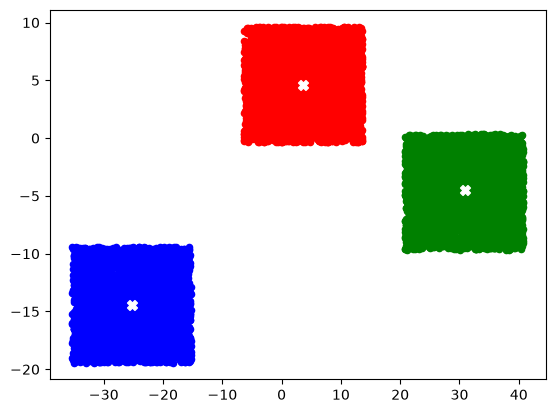

In [92]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random
import math


def rast(x1, y1, x2, y2):
    return math.sqrt(float(x1 - x2) ** 2 + float(y1 - y2) ** 2)


df1 = pd.read_excel('/Users/viarg/Downloads/cluster_ege/EGE/3.xlsx', header=None, skiprows = 1)
plt.scatter(df1.iloc[:, 0].values, df1.iloc[:, 1].values, color = 'red', s = 0.1)

toch = df1.iloc[:, :2].values

i1 = random.randint(0, len(toch) - 1)
i2 = random.randint(0, len(toch) - 1)
i3 = random.randint(0, len(toch) - 1)
while i2 == i1:
    i2 = random.randint(0, len(toch) - 1)
while i3 == i2:
    i3 = random.randint(0, len(toch) - 1)

c1 = toch[i1]
c2 = toch[i2]
c3 = toch[i3]

s11 = 0
s12 = 0
s21 = 0
s22 = 0
s31 = 0
s32 = 0

p1 = []
p2 = []
p3 = []

for i in range(len(toch)):
    x3 = toch[i][0]
    y3 = toch[i][1]
    r1 = rast(c1[0], c1[1], x3, y3)
    r2 = rast(c2[0], c2[1], x3, y3)
    r3 = rast(c3[0], c3[1], x3, y3)
    
    if min(r1, r2, r3) == r1:
        s11 += x3
        s12 += y3
        p1.append((x3, y3))
        c1[0] = s11 / len(p1)
        c1[1] = s12 / len(p1)
    elif min(r1, r2, r3) == r2:
        s21 += x3
        s22 += y3
        p2.append((x3, y3))
        c2[0] = s21 / len(p2)
        c2[1] = s22 / len(p2)
    else:
        s31 += x3
        s32 += y3
        p3.append((x3, y3))
        c3[0] = s31 / len(p3)
        c3[1] = s32 / len(p3)


        
p1 = np.array(p1)
p2 = np.array(p2)
p3 = np.array(p3)

x_p1 = p1[:, 0]
y_p1 = p1[:, 1]

x_p2 = p2[:, 0]
y_p2 = p2[:, 1]

x_p3 = p3[:, 0]
y_p3 = p3[:, 1]

diff = p1[:, np.newaxis, :] - p1[np.newaxis, :, :]
distances = np.sqrt((diff ** 2).sum(axis=-1))
sums = distances.sum(axis=1)
ind1 = np.argmin(sums)

plt.scatter(p1[ind1][0], p1[ind1][1], color = 'white', s = 50, marker = 'X', zorder=10)

diff = p2[:, np.newaxis, :] - p2[np.newaxis, :, :]
distances = np.sqrt((diff ** 2).sum(axis=-1))
sums = distances.sum(axis=1)
ind2 = np.argmin(sums)

plt.scatter(p2[ind2][0], p2[ind2][1], color = 'white', s = 50, marker = 'X', zorder=10)

diff = p3[:, np.newaxis, :] - p3[np.newaxis, :, :]
distances = np.sqrt((diff ** 2).sum(axis=-1))
sums = distances.sum(axis=1)
ind3 = np.argmin(sums)

plt.scatter(p3[ind3][0], p3[ind3][1], color = 'white', s = 50, marker = 'X', zorder=10)

all = np.array([p1[ind1], p2[ind2], p3[ind3]])
print("Ответ:", *np.mean(all, axis=0) * 1000)

plt.scatter(x_p1, y_p1, color='red', s=20)
plt.scatter(x_p2, y_p2, color='blue', s=20)

plt.scatter(x_p3, y_p3, color='green', s=20)

plt.show()


Ответ: 2575.059367337816 5013.97331897093


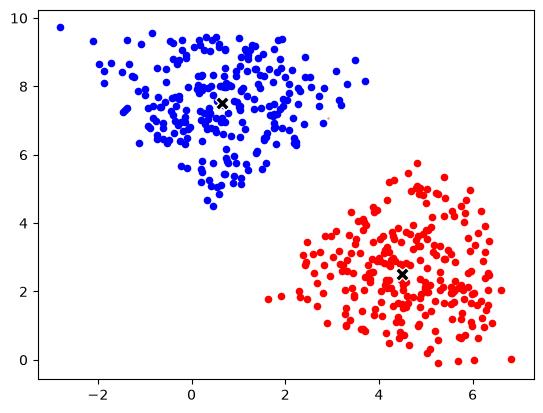

In [94]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random
import math


def rast(x1, y1, x2, y2):
    return math.sqrt(float(x1 - x2) ** 2 + float(y1 - y2) ** 2)


df1 = pd.read_excel('/Users/viarg/Downloads/cluster_ege/EGE/4.xlsx', header=None, skiprows = 1)
plt.scatter(df1.iloc[:, 0].values, df1.iloc[:, 1].values, color = 'red', s = 0.1)

toch = df1.iloc[:, :2].values

i1 = random.randint(0, len(toch) - 1)
i2 = random.randint(0, len(toch) - 1)
while i2 == i1:
    i2 = random.randint(0, len(toch) - 1)


c1 = toch[i1]
c2 = toch[i2]

s11 = 0
s12 = 0
s21 = 0
s22 = 0

p1 = []
p2 = []
for i in range(len(toch)):
    x3 = toch[i][0]
    y3 = toch[i][1]
    r1 = rast(c1[0], c1[1], x3, y3)
    r2 = rast(c2[0], c2[1], x3, y3)
    
    if min(r1, r2) == r1:
        s11 += x3
        s12 += y3
        p1.append((x3, y3))
        c1[0] = s11 / len(p1)
        c1[1] = s12 / len(p1)
    else:
        s21 += x3
        s22 += y3
        p2.append((x3, y3))
        c2[0] = s21 / len(p2)
        c2[1] = s22 / len(p2)


        
p1 = np.array(p1)
p2 = np.array(p2)

x_p1 = p1[:, 0]
y_p1 = p1[:, 1]

x_p2 = p2[:, 0]
y_p2 = p2[:, 1]

diff = p1[:, np.newaxis, :] - p1[np.newaxis, :, :]
distances = np.sqrt((diff ** 2).sum(axis=-1))
sums = distances.sum(axis=1)
ind1 = np.argmin(sums)

plt.scatter(p1[ind1][0], p1[ind1][1], color = 'black', s = 100, marker = 'X', zorder=10, edgecolors='white')

diff = p2[:, np.newaxis, :] - p2[np.newaxis, :, :]
distances = np.sqrt((diff ** 2).sum(axis=-1))
sums = distances.sum(axis=1)
ind2 = np.argmin(sums)

plt.scatter(p2[ind2][0], p2[ind2][1], color = 'black', s = 100, marker = 'X', zorder=10, edgecolors='white')

all = np.array([p1[ind1], p2[ind2]])
print("Ответ:", *np.mean(all, axis=0) * 1000)

plt.scatter(x_p1, y_p1, color='red', s=20)
plt.scatter(x_p2, y_p2, color='blue', s=20)


plt.show()


Ответ: 56.76327124073577 3749.349222295142


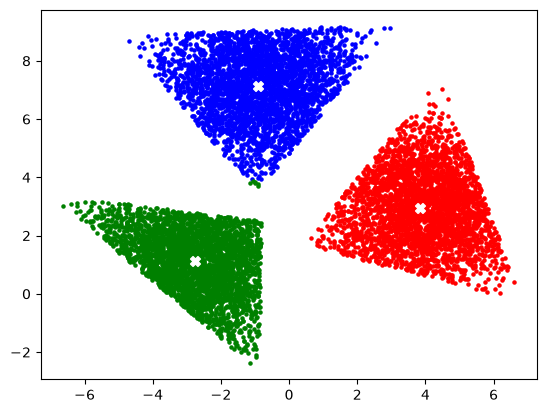

In [121]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random
import math


def rast(x1, y1, x2, y2):
    return math.sqrt(float(x1 - x2) ** 2 + float(y1 - y2) ** 2)


df1 = pd.read_excel('/Users/viarg/Downloads/cluster_ege/EGE/5.xlsx', header=None, skiprows = 1)
plt.scatter(df1.iloc[:, 0].values, df1.iloc[:, 1].values, color = 'red', s = 0.1)

toch = df1.iloc[:, :2].values

i1 = random.randint(0, len(toch) - 1)
i2 = random.randint(0, len(toch) - 1)
i3 = random.randint(0, len(toch) - 1)

while i2 == i1:
    i2 = random.randint(0, len(toch) - 1)
while i3 == i2:
    i3 = random.randint(0, len(toch) - 1)

c1 = toch[i1]
c2 = toch[i2]
c3 = toch[i3]

s11 = 0
s12 = 0
s21 = 0
s22 = 0
s31 = 0
s32 = 0

p1 = []
p2 = []
p3 = []

for i in range(len(toch)):
    x3 = toch[i][0]
    y3 = toch[i][1]
    r1 = rast(c1[0], c1[1], x3, y3)
    r2 = rast(c2[0], c2[1], x3, y3)
    r3 = rast(c3[0], c3[1], x3, y3)
    
    if min(r1, r2, r3) == r1:
        s11 += x3
        s12 += y3
        p1.append((x3, y3))
        c1[0] = s11 / len(p1)
        c1[1] = s12 / len(p1)
    elif min(r1, r2, r3) == r2:
        s21 += x3
        s22 += y3
        p2.append((x3, y3))
        c2[0] = s21 / len(p2)
        c2[1] = s22 / len(p2)
    else:
        s31 += x3
        s32 += y3
        p3.append((x3, y3))
        c3[0] = s31 / len(p3)
        c3[1] = s32 / len(p3)


        
p1 = np.array(p1)
p2 = np.array(p2)
p3 = np.array(p3)

x_p1 = p1[:, 0]
y_p1 = p1[:, 1]

x_p2 = p2[:, 0]
y_p2 = p2[:, 1]

x_p3 = p3[:, 0]
y_p3 = p3[:, 1]

diff = p1[:, np.newaxis, :] - p1[np.newaxis, :, :]
distances = np.sqrt((diff ** 2).sum(axis=-1))
sums = distances.sum(axis=1)
ind1 = np.argmin(sums)

plt.scatter(p1[ind1][0], p1[ind1][1], color = 'white', s = 50, marker = 'X', zorder=10)

diff = p2[:, np.newaxis, :] - p2[np.newaxis, :, :]
distances = np.sqrt((diff ** 2).sum(axis=-1))
sums = distances.sum(axis=1)
ind2 = np.argmin(sums)

plt.scatter(p2[ind2][0], p2[ind2][1], color = 'white', s = 50, marker = 'X', zorder=10)

diff = p3[:, np.newaxis, :] - p3[np.newaxis, :, :]
distances = np.sqrt((diff ** 2).sum(axis=-1))
sums = distances.sum(axis=1)
ind3 = np.argmin(sums)

plt.scatter(p3[ind3][0], p3[ind3][1], color = 'white', s = 50, marker = 'X', zorder=10)

all = np.array([p1[ind1], p2[ind2], p3[ind3]])
print("Ответ:", *np.mean(all, axis=0) * 1000)

plt.scatter(x_p1, y_p1, color = 'red', s = 5)
plt.scatter(x_p2, y_p2, color = 'blue', s = 5)
plt.scatter(x_p3, y_p3, color = 'green', s = 5)

plt.show()


# Кластеризация (0.75 за каждый алгоритм на всех данных)

На предложенных распределениях данных проверьте предложенные алгоритмы. Постройте графики кластеризации для каждой пары алгоритм-данные, разные кластеры покрасьте разным цветом. Воспользуйтесь sklearn реализациями. Параметры кластеризации для разных алгоритмов подберите такие, чтобы алгоритмы можно было сравнивать (по возможности одинаковое количество кластеров и т.д.)

In [12]:
!pip install xlrd

In [ ]:
two_means =  
dbscan = 

clustering_algorithms = (
        ("MiniBatch\nKMeans", two_means),
        ("DBSCAN", dbscan),
    )

In [ ]:
np.random.seed(0)

# ============
# Generate datasets. We choose the size big enough to see the scalability
# of the algorithms, but not too big to avoid too long running times
# ============
n_samples = 1500
noisy_circles = datasets.make_circles(n_samples=n_samples, factor=0.5, noise=0.05)
noisy_moons = datasets.make_moons(n_samples=n_samples, noise=0.05)
blobs = datasets.make_blobs(n_samples=n_samples, random_state=8)
no_structure = np.random.rand(n_samples, 2), None

# Anisotropicly distributed data
random_state = 170
X, y = datasets.make_blobs(n_samples=n_samples, random_state=random_state)
transformation = [[0.6, -0.6], [-0.4, 0.8]]
X_aniso = np.dot(X, transformation)
aniso = (X_aniso, y)

# blobs with varied variances
varied = datasets.make_blobs(
    n_samples=n_samples, cluster_std=[1.0, 2.5, 0.5], random_state=random_state
)

# ============
# Set up cluster parameters
# ============
plt.figure(figsize=(9 * 2 + 3, 13))
plt.subplots_adjust(
    left=0.02, right=0.98, bottom=0.001, top=0.95, wspace=0.05, hspace=0.01
)

plot_num = 1

default_base = {
    "quantile": 0.3,
    "eps": 0.3,
    "damping": 0.9,
    "preference": -200,
    "n_neighbors": 10,
    "n_clusters": 3,
    "min_samples": 20,
    "xi": 0.05,
    "min_cluster_size": 0.1,
}

datasets = [
    (
        noisy_circles,
        {
            "damping": 0.77,
            "preference": -240,
            "quantile": 0.2,
            "n_clusters": 2,
            "min_samples": 20,
            "xi": 0.25,
        },
    ),
    (noisy_moons, {"damping": 0.75, "preference": -220, "n_clusters": 2}),
    (
        varied,
        {
            "eps": 0.18,
            "n_neighbors": 2,
            "min_samples": 5,
            "xi": 0.035,
            "min_cluster_size": 0.2,
        },
    ),
    (
        aniso,
        {
            "eps": 0.15,
            "n_neighbors": 2,
            "min_samples": 20,
            "xi": 0.1,
            "min_cluster_size": 0.2,
        },
    ),
    (blobs, {}),
    (no_structure, {}),
]

for i_dataset, (dataset, algo_params) in enumerate(datasets):
    # update parameters with dataset-specific values
    params = default_base.copy()
    params.update(algo_params)

    X, y = dataset

    # normalize dataset for easier parameter selection
    X = StandardScaler().fit_transform(X)

    # estimate bandwidth for mean shift
    bandwidth = cluster.estimate_bandwidth(X, quantile=params["quantile"])

    # connectivity matrix for structured Ward
    connectivity = kneighbors_graph(
        X, n_neighbors=params["n_neighbors"], include_self=False
    )
    # make connectivity symmetric
    connectivity = 0.5 * (connectivity + connectivity.T)

    for name, algorithm in clustering_algorithms:
        t0 = time.time()